In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


# phase 1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("bank.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", data.shape)

data.head()

Dataset loaded successfully!
Dataset shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
print("Dataset shape:", data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nDataset information:")
data.info()


Dataset shape: (11162, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-nu

In [4]:
# Count customer responses
print(data["deposit"].value_counts())

# Calculate response percentages
response_percentage = (
    data["deposit"].value_counts(normalize=True) * 100
).round(2)

print("\nResponse percentages:")
print(response_percentage)


deposit
no     5873
yes    5289
Name: count, dtype: int64

Response percentages:
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64


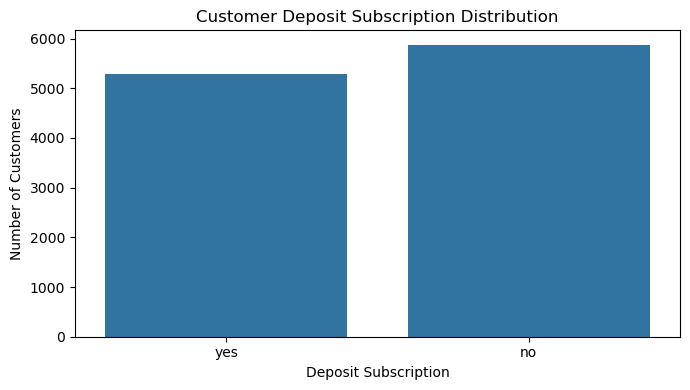

In [5]:

plt.figure(figsize=(7, 4))

sns.countplot(data=data, x="deposit")

plt.title("Customer Deposit Subscription Distribution")
plt.xlabel("Deposit Subscription")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [6]:
print("Total missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())


Total missing values: 0
Duplicate rows: 0


# phase 2

In [7]:

# Check missing values
print("Missing values:")
print(data.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", data.duplicated().sum())

# Check target categories
print("\nTarget values:")
print(data["deposit"].value_counts())


Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Duplicate records: 0

Target values:
deposit
no     5873
yes    5289
Name: count, dtype: int64


In [8]:

# Remove duplicate records
data = data.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", data.shape)

Dataset shape after removing duplicates: (11162, 17)


In [9]:

# Separate features (X) and target (y)
X = data.drop(columns=["deposit", "duration"])
y = data["deposit"].map({"no": 0, "yes": 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget mapping:")
print("No subscription = 0")
print("Subscription = 1")


Input features shape: (11162, 15)
Target shape: (11162,)

Target mapping:
No subscription = 0
Subscription = 1


In [10]:

# Identify column types
numeric_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)


Numerical columns:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [11]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Preprocess numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [12]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 8929
Testing records: 2233

Training target distribution:
deposit
0    0.526
1    0.474
Name: proportion, dtype: float64

Testing target distribution:
deposit
0    0.526
1    0.474
Name: proportion, dtype: float64


# phase 3

In [13]:

from sklearn.tree import DecisionTreeClassifier

# Create the complete machine learning pipeline
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [14]:

# Predict customer responses on the test data
y_pred_dt = decision_tree.predict(X_test)

print("First 20 actual responses:")
print(y_test.iloc[:20].values)

print("\nFirst 20 predicted responses:")
print(y_pred_dt[:20])


First 20 actual responses:
[0 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 0 0 1]

First 20 predicted responses:
[1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 0 1]


In [15]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))


Decision Tree Accuracy: 68.65%

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.67      0.79      0.73      1175
   Subscription       0.71      0.57      0.63      1058

       accuracy                           0.69      2233
      macro avg       0.69      0.68      0.68      2233
   weighted avg       0.69      0.69      0.68      2233



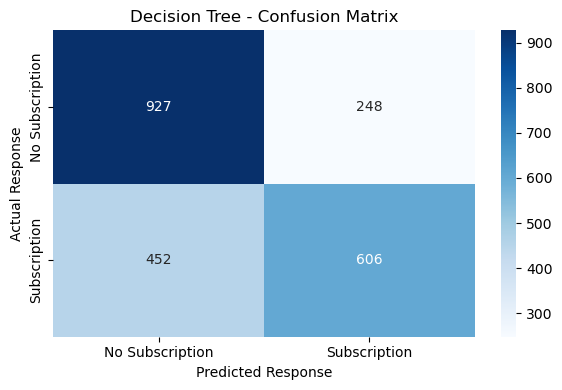

In [16]:

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Response")
plt.ylabel("Actual Response")
plt.tight_layout()
plt.show()


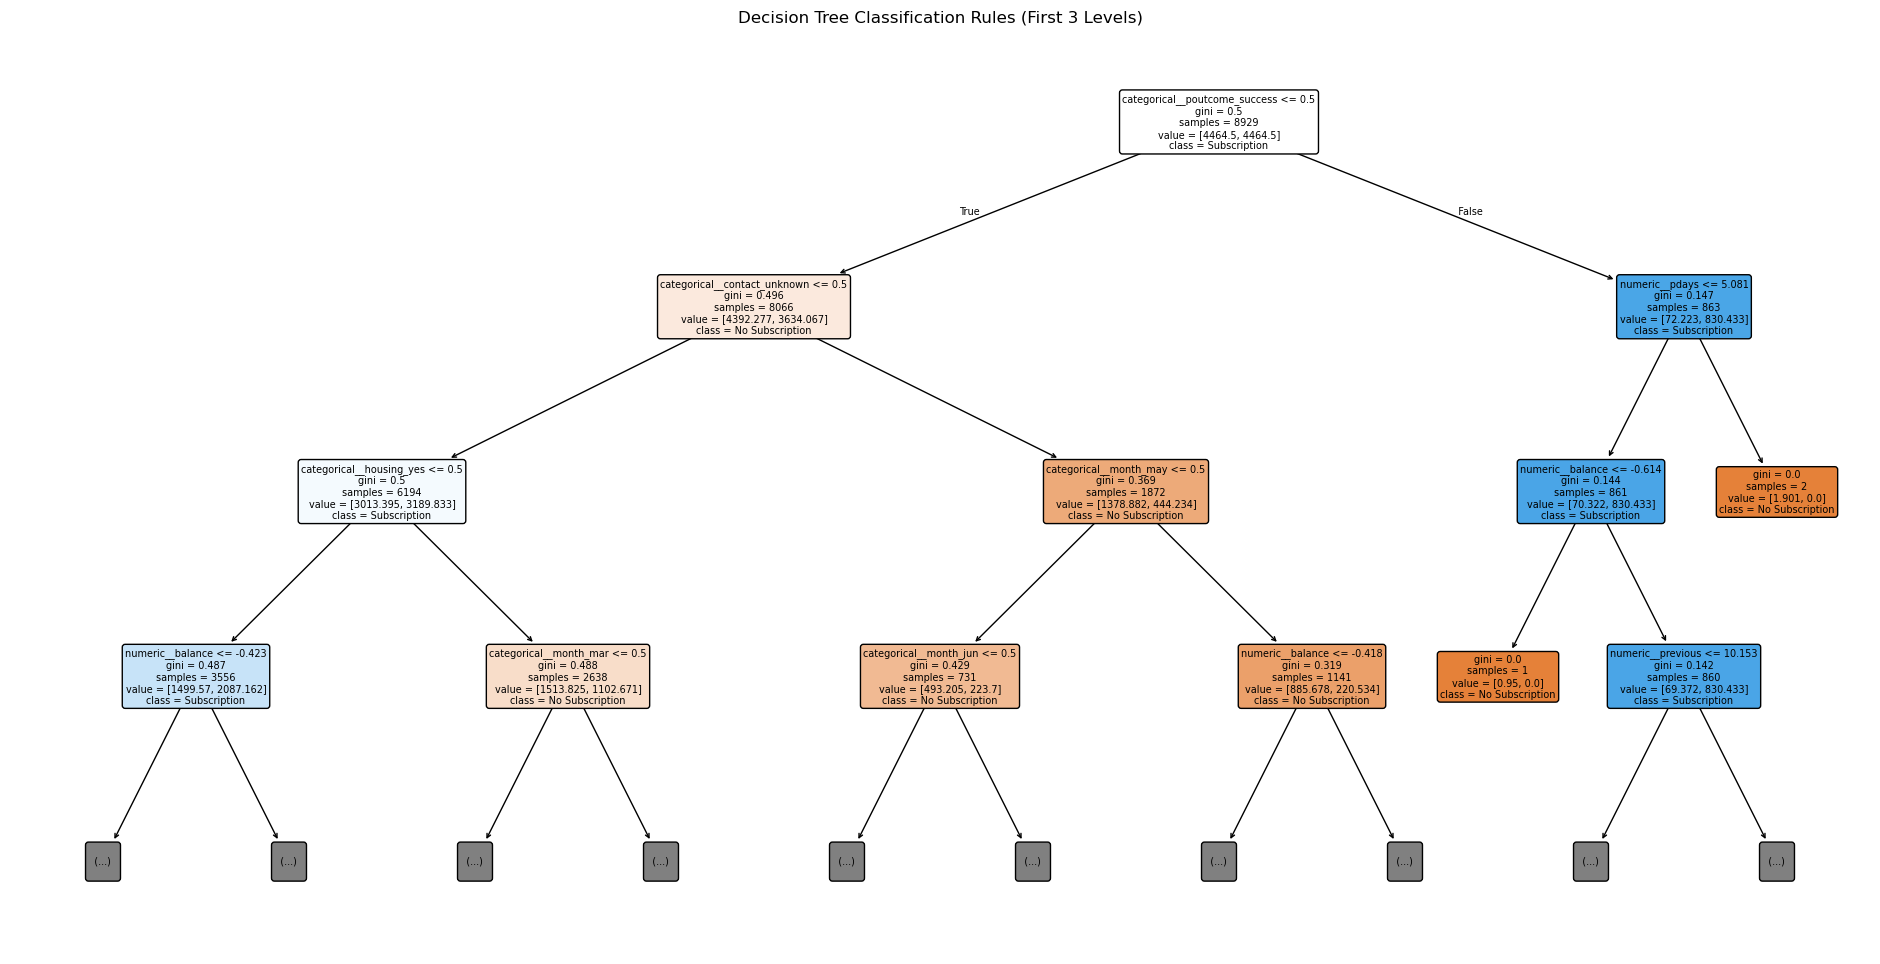

In [17]:

from sklearn.tree import plot_tree

# Get the trained tree and its encoded feature names
trained_tree = decision_tree.named_steps["classifier"]
feature_names = decision_tree.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=["No Subscription", "Subscription"],
    filled=True,
    rounded=True,
    fontsize=7,
    max_depth=3
)

plt.title("Decision Tree Classification Rules (First 3 Levels)")
plt.show()


# phase 4

In [18]:

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [19]:

# Predict responses on the test dataset
y_pred_lr = logistic_model.predict(X_test)

print("First 20 actual responses:")
print(y_test.iloc[:20].values)

print("\nFirst 20 predicted responses:")
print(y_pred_lr[:20])


First 20 actual responses:
[0 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 0 0 1]

First 20 predicted responses:
[0 1 1 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1]


In [20]:

from sklearn.metrics import accuracy_score, classification_report

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {accuracy_lr * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))


Logistic Regression Accuracy: 69.32%

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.68      0.78      0.73      1175
   Subscription       0.71      0.59      0.65      1058

       accuracy                           0.69      2233
      macro avg       0.70      0.69      0.69      2233
   weighted avg       0.70      0.69      0.69      2233



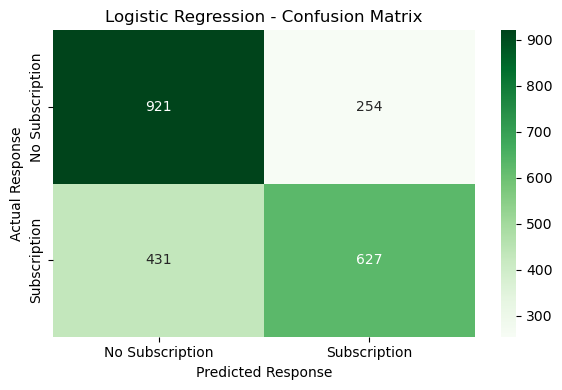

In [21]:

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Response")
plt.ylabel("Actual Response")
plt.tight_layout()
plt.show()


In [22]:

from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Algorithm": ["Decision Tree", "Logistic Regression"],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred_dt) * 100,
        accuracy_score(y_test, y_pred_lr) * 100
    ],
    "Precision (%)": [
        precision_score(y_test, y_pred_dt, zero_division=0) * 100,
        precision_score(y_test, y_pred_lr, zero_division=0) * 100
    ],
    "Recall (%)": [
        recall_score(y_test, y_pred_dt, zero_division=0) * 100,
        recall_score(y_test, y_pred_lr, zero_division=0) * 100
    ],
    "F1-score (%)": [
        f1_score(y_test, y_pred_dt, zero_division=0) * 100,
        f1_score(y_test, y_pred_lr, zero_division=0) * 100
    ]
})

results = results.round(2)
results


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Decision Tree,68.65,70.96,57.28,63.39
1,Logistic Regression,69.32,71.17,59.26,64.67


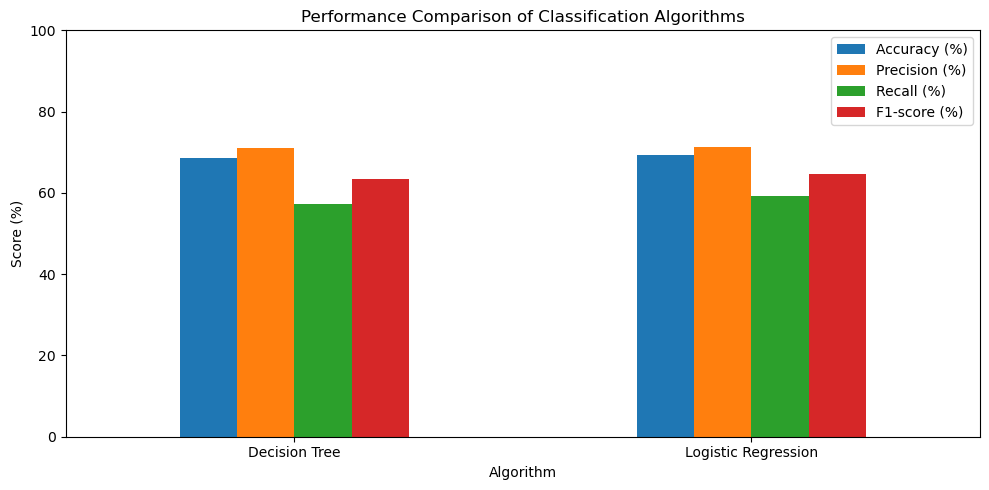

In [23]:

results_plot = results.set_index("Algorithm")[
    ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-score (%)"]
]

results_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Performance Comparison of Classification Algorithms")
plt.ylabel("Score (%)")
plt.xlabel("Algorithm")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


# phase 5

In [24]:

# Create a sample customer
customer = pd.DataFrame([{
    "age": 35,
    "job": "management",
    "marital": "married",
    "education": "tertiary",
    "default": "no",
    "balance": 1500,
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "day": 15,
    "month": "may",
    "campaign": 2,
    "pdays": -1,
    "previous": 0,
    "poutcome": "unknown"
}])

# Ensure the input columns match the training features
customer = customer[X.columns]

# Predict with both algorithms
dt_prediction = decision_tree.predict(customer)[0]
lr_prediction = logistic_model.predict(customer)[0]

dt_probability = decision_tree.predict_proba(customer)[0][1]
lr_probability = logistic_model.predict_proba(customer)[0][1]

print("CUSTOMER RESPONSE PREDICTION")
print("-" * 35)

print("Decision Tree:",
      "Likely to subscribe" if dt_prediction == 1
      else "Unlikely to subscribe")

print(f"Decision Tree subscription probability: {dt_probability:.2%}")

print("\nLogistic Regression:",
      "Likely to subscribe" if lr_prediction == 1
      else "Unlikely to subscribe")

print(f"Logistic Regression subscription probability: {lr_probability:.2%}")


CUSTOMER RESPONSE PREDICTION
-----------------------------------
Decision Tree: Unlikely to subscribe
Decision Tree subscription probability: 39.83%

Logistic Regression: Unlikely to subscribe
Logistic Regression subscription probability: 44.64%


In [25]:

print("FINAL MODEL COMPARISON")
display(results)

best_model = results.loc[results["F1-score (%)"].idxmax(), "Algorithm"]
print("Model with the highest F1-score:", best_model)


FINAL MODEL COMPARISON


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Decision Tree,68.65,70.96,57.28,63.39
1,Logistic Regression,69.32,71.17,59.26,64.67


Model with the highest F1-score: Logistic Regression


In [26]:

results.to_csv("model_comparison.csv", index=False)
print("Model comparison saved to model_comparison.csv")


Model comparison saved to model_comparison.csv
